# 07 - Are the explanations faithful? Insertion and deletion over all 6,000 pairs

Measures how much the saliency maps actually explain, before any attack touches them.
Notebook 09 repeats exactly these measurements on the attacked images, so this is the
baseline half of that comparison.

The claim the project is building toward is that an attack makes the explanation wrong.
That is not measurable until two things exist. First, a number for how good the
explanation is to begin with: so far the only evidence has been that the maps look
sensible on a handful of hand-picked pairs, which is an impression rather than a
measurement. Second, a floor. An insertion AUC of 0.41 after an attack means nothing on
its own; it only means something against what a random map scores on the same pairs.
Both are computed here, over the whole set.

## What insertion and deletion measure

Both perturb the **probe** image and watch its cosine similarity to the untouched
**reference**, revealing or removing pixels in the order the saliency map ranks them.

| | Procedure | A faithful map... | So we want |
|---|---|---|---|
| **Deletion** | start from the probe, progressively replace the most salient pixels with mid-grey | destroys the match immediately | **low AUC** |
| **Insertion** | start from a blurred probe, progressively restore the most salient pixels | rebuilds the match immediately | **high AUC** |

If a map is uninformative, both curves approach the straight line you would get by
removing pixels at random, which is what the `random` control traces out.

## The four maps compared

* **gradient** - `mean_c (d cos / d probe)^2`. Cheap, differentiable, and the map the
  attack in notebook 09 targets.
* **xssab** - our implementation of Huber et al., WACV 2024. Splits the similarity into
  per-dimension arguments that support the match (actor) and oppose it (counteractor),
  and back-propagates each separately. This follows the published algorithm rather than
  the `grad x input` stand-in used earlier; see the method's docstring.
* **xface** - occlusion. Uses no gradients at all, which makes it the honest control for
  whether an attack changed the model's behaviour or merely disturbed its gradient.
* **random** - uniform noise. The floor.

## Cost

About 369 forward passes per pair: 196 for the xFace occlusion maps and 168 for the four
sets of insertion/deletion curves, so roughly 2.2M passes over 6,000 pairs. The gradient
and xSSAB maps are noise by comparison at 5 passes.

Pairs are independent, so the loop is split across all visible GPUs, each with its own
replica of the model and its own chunks. On Kaggle's *GPU T4 x2* that roughly halves the
wall time; `N_GPUS = 1` forces the single-device path. Set `MAX_PAIRS` to a few hundred
for a smoke test before committing to the full run.

## CONFIG - edit only this cell


In [15]:
import torch

# =================================================================
# PATHS - update to match your Kaggle dataset / model slugs
# =================================================================
IMAGES_DIR   = "/kaggle/input/datasets/xitij27/hcml-lfw-dataset/imgs"
WEIGHTS_PATH = "/kaggle/input/models/xitij27/elastic-face-arc/pytorch/default/1/ElasticFaceArc.pth"
OUTPUT_DIR   = "/kaggle/working/"

# =================================================================
# DATASET LAYOUT  -  the fix for feedback point 1
# =================================================================
# The image directory holds 12,000 files (0.jpg .. 11999.jpg), i.e. 6,000
# pairs, NOT the 900 pairs used in notebooks 01-05.  Consecutive images form
# a pair (0,1), (2,3), ...  The pairs follow the standard LFW view-2 layout:
# 10 folds x 600 pairs, and each fold is 300 genuine pairs followed by 300
# imposter pairs.  Notebook 06 verifies this empirically before use.
N_IMAGES         = 12000
N_PAIRS          = N_IMAGES // 2      # 6000
PAIRS_PER_FOLD   = 600
GENUINE_PER_FOLD = 300
N_FOLDS          = N_PAIRS // PAIRS_PER_FOLD   # 10

# =================================================================
# PROBE / REFERENCE  -  the fix for feedback point 4
# =================================================================
# An attack may modify exactly ONE image of a pair: the "probe".  The other
# image, the "reference", is never touched.  PROBE_SIDE="random" picks the
# side with a seeded per-pair coin flip, so the attacked image is not
# systematically image 0 of every pair while the run stays reproducible.
PROBE_SIDE = "random"        # 0 | 1 | "random"
PROBE_SEED = 20260728

# =================================================================
# MODEL
# =================================================================
NUM_FEATURES = 512
IMG_SIZE     = 112

# =================================================================
# THIS NOTEBOOK
# =================================================================
MAX_PAIRS = None          # None = all 6,000 pairs.  Set e.g. 400 for a quick run.
EVAL_BATCH = 64           # pairs per chunk; each chunk goes to one GPU

XAI_METHODS_TO_EVAL = ["gradient", "xssab", "xface", "random"]

# --- xSSAB ---------------------------------------------------------------
# Dimensions of the per-dimension similarity argument e_probe[d]*e_ref[d] are
# split at XSSAB_THR / D.  0.0 splits on the sign of the argument.
XSSAB_THR = 0.0

# --- xFace occlusion -----------------------------------------------------
XFACE_GRID          = 14     # 14x14 cells over 112x112 -> 8x8 px cells, 196 passes/map
XFACE_OCC_BATCH     = 196    # all cells of one map in a single forward pass
XFACE_OCCLUDE_VALUE = 0.0    # mid-grey in [-1,1] space

# --- random control ------------------------------------------------------
RANDOM_SALIENCY_SEED = 1234

# --- insertion / deletion ------------------------------------------------
INSDEL_STEPS      = 20       # 21 points from 0% to 100% of pixels
DELETE_VALUE      = 0.0      # what deleted pixels become (mid-grey)
INSERT_BLUR_SIGMA = 8.0      # blur of the insertion starting point

TOPK_FRAC        = 0.10
CHECKPOINT_EVERY = 500

# Pairs shown in the qualitative figure.  Remember the layout when changing
# these: genuine pairs are those with (pair % 600) < 300, everything else is
# an imposter pair.  Verified against notebook 06's scores:
#   0 (+0.73), 1200 (+0.78), 3000 (+0.65) genuine | 300 (-0.00), 3300 (-0.08) imposter
VIZ_GENUINE_PAIRS  = [0, 1200, 3000]
VIZ_IMPOSTER_PAIRS = [300, 3300]
assert all((p % 600) < 300 for p in VIZ_GENUINE_PAIRS), "a VIZ_GENUINE pair is not genuine"
assert all((p % 600) >= 300 for p in VIZ_IMPOSTER_PAIRS), "a VIZ_IMPOSTER pair is not imposter"

# =================================================================
# RUNTIME
# =================================================================
USE_AMP        = True     # fp16 autocast for EVALUATION forward passes only
                          # (never inside an attack loop - see notebook 08/09)
EMBED_BATCH    = 128      # batch size for plain embedding extraction
PRELOAD_IMAGES = True     # cache all 12,000 images in RAM (~450 MB)
N_GPUS         = None     # None = use every visible GPU.  Kaggle's "GPU T4 x2"
                          # exposes two; set to 1 to force single-GPU.

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Primary device : {DEVICE}")
for _i in range(torch.cuda.device_count()):
    _p = torch.cuda.get_device_properties(_i)
    print(f"  cuda:{_i} : {_p.name}  {_p.total_memory / 1e9:.1f} GB")

Primary device : cuda
  cuda:0 : Tesla T4  15.6 GB
  cuda:1 : Tesla T4  15.6 GB


## Imports


In [16]:
import os
import json
import math
import numpy as np
import cv2
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from contextlib import nullcontext
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings("ignore")

np.random.seed(0)
torch.manual_seed(0)
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

## Backbone


In [17]:
def conv3x3(in_planes, out_planes, stride=1, groups=1, dilation=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                     padding=dilation, groups=groups, bias=False, dilation=dilation)

def conv1x1(in_planes, out_planes, stride=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


class IBasicBlock(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None,
                 groups=1, base_width=64, dilation=1, use_se=False):
        super().__init__()
        self.bn1        = nn.BatchNorm2d(inplanes, eps=1e-05)
        self.conv1      = conv3x3(inplanes, planes)
        self.bn2        = nn.BatchNorm2d(planes, eps=1e-05)
        self.prelu      = nn.PReLU(planes)
        self.conv2      = conv3x3(planes, planes, stride)
        self.bn3        = nn.BatchNorm2d(planes, eps=1e-05)
        self.downsample = downsample
        self.stride     = stride

    def forward(self, x):
        identity = x
        out = self.bn1(x)
        out = self.conv1(out)
        out = self.bn2(out)
        out = self.prelu(out)
        out = self.conv2(out)
        out = self.bn3(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return out


class IResNet(nn.Module):
    fc_scale = 7 * 7
    def __init__(self, block, layers, dropout=0, num_features=512,
                 groups=1, width_per_group=64,
                 replace_stride_with_dilation=None):
        super().__init__()
        self.inplanes   = 64
        self.dilation   = 1
        if replace_stride_with_dilation is None:
            replace_stride_with_dilation = [False, False, False]
        self.groups     = groups
        self.base_width = width_per_group
        self.conv1      = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1        = nn.BatchNorm2d(64, eps=1e-05)
        self.prelu      = nn.PReLU(64)
        self.layer1     = self._make_layer(block, 64,  layers[0], stride=2)
        self.layer2     = self._make_layer(block, 128, layers[1], stride=2,
                                           dilate=replace_stride_with_dilation[0])
        self.layer3     = self._make_layer(block, 256, layers[2], stride=2,
                                           dilate=replace_stride_with_dilation[1])
        self.layer4     = self._make_layer(block, 512, layers[3], stride=2,
                                           dilate=replace_stride_with_dilation[2])
        self.bn2        = nn.BatchNorm2d(512 * block.expansion, eps=1e-05)
        self.dropout    = nn.Dropout(p=dropout, inplace=True)
        self.fc         = nn.Linear(512 * block.expansion * self.fc_scale, num_features)
        self.features   = nn.BatchNorm1d(num_features, eps=1e-05)
        nn.init.constant_(self.features.weight, 1.0)
        self.features.weight.requires_grad = False
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0, 0.1)
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, planes, num_blocks, stride=1, dilate=False):
        downsample    = None
        prev_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                nn.BatchNorm2d(planes * block.expansion, eps=1e-05),
            )
        layers = [block(self.inplanes, planes, stride, downsample,
                        self.groups, self.base_width, prev_dilation)]
        self.inplanes = planes * block.expansion
        for _ in range(1, num_blocks):
            layers.append(block(self.inplanes, planes, groups=self.groups,
                                base_width=self.base_width, dilation=self.dilation))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.prelu(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.bn2(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        x = self.features(x)
        return x


def elastic_iresnet100(**kwargs):
    return IResNet(IBasicBlock, [3, 13, 30, 3], **kwargs)

## Data, threshold and plotting utilities


In [18]:
# ---------------------------------------------------------------- images ---
def preprocess(img_rgb):
    """(H,W,3) uint8 RGB -> (3,H,W) float32 tensor in [-1, 1]."""
    x = ((img_rgb.astype(np.float32) / 255.0) - 0.5) / 0.5
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))


IMAGE_CACHE = None

def _read_image(img_idx):
    path = os.path.join(IMAGES_DIR, f"{img_idx}.jpg")
    bgr = cv2.imread(path)
    if bgr is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def preload_images(n=N_IMAGES):
    """Hold every image in RAM so the long loops never re-decode a JPEG."""
    global IMAGE_CACHE
    cache = np.zeros((n, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    for i in tqdm(range(n), desc="Caching images", leave=False):
        cache[i] = _read_image(i)
    IMAGE_CACHE = cache
    print(f"Cached {n:,} images ({cache.nbytes / 1e6:.0f} MB)")


def image_rgb(img_idx):
    return IMAGE_CACHE[img_idx] if IMAGE_CACHE is not None else _read_image(img_idx)


def image_tensor(img_idx):
    return preprocess(image_rgb(img_idx))


def tensor_to_uint8(t):
    """(3,H,W) or (1,3,H,W) float tensor in [-1,1] -> (H,W,3) uint8."""
    x = t.detach().float().cpu().numpy()
    if x.ndim == 4:
        x = x[0]
    x = x.transpose(1, 2, 0)
    return np.clip((x * 0.5 + 0.5) * 255, 0, 255).astype(np.uint8)


# ------------------------------------------------------- pair bookkeeping ---
def _build_probe_sides():
    if PROBE_SIDE in (0, 1):
        return np.full(N_PAIRS, int(PROBE_SIDE), dtype=np.int64)
    if PROBE_SIDE != "random":
        raise ValueError(f"PROBE_SIDE must be 0, 1 or 'random', got {PROBE_SIDE!r}")
    return np.random.RandomState(PROBE_SEED).randint(0, 2, size=N_PAIRS)

PROBE_SIDES = _build_probe_sides()


def probe_reference(pair_idx):
    """(probe_img_idx, reference_img_idx) - always two DIFFERENT image files.

    The probe is the ONLY image any attack in this project is allowed to
    modify; the reference is passed through the model untouched.
    """
    i0, i1 = 2 * int(pair_idx), 2 * int(pair_idx) + 1
    probe, ref = (i0, i1) if PROBE_SIDES[pair_idx] == 0 else (i1, i0)
    assert probe != ref, "probe and reference must be two different images"
    return probe, ref


def is_genuine(pair_idx):
    """LFW view-2: every fold is 300 genuine pairs then 300 imposter pairs."""
    return (np.asarray(pair_idx) % PAIRS_PER_FOLD) < GENUINE_PER_FOLD


def fold_of(pair_idx):
    return np.asarray(pair_idx) // PAIRS_PER_FOLD


PAIR_IDX   = np.arange(N_PAIRS)
IS_GENUINE = is_genuine(PAIR_IDX)
FOLD       = fold_of(PAIR_IDX)
PROBE_IMG  = np.where(PROBE_SIDES == 0, 2 * PAIR_IDX, 2 * PAIR_IDX + 1)
REF_IMG    = np.where(PROBE_SIDES == 0, 2 * PAIR_IDX + 1, 2 * PAIR_IDX)


def load_pair_batch(pair_indices, device=None):
    """-> (probes, references), each (B,3,112,112) on DEVICE."""
    device = device or DEVICE
    probes = torch.stack([image_tensor(int(PROBE_IMG[i])) for i in pair_indices]).to(device)
    refs   = torch.stack([image_tensor(int(REF_IMG[i]))   for i in pair_indices]).to(device)
    return probes, refs


# ----------------------------------------------------------------- model ---
def amp_ctx(device=None):
    dev = DEVICE if device is None else device
    if USE_AMP and dev.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def load_model_on(dev):
    m = elastic_iresnet100(num_features=NUM_FEATURES)
    state = torch.load(WEIGHTS_PATH, map_location="cpu")
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    m.load_state_dict(state)
    m = m.to(dev).eval()
    # We only ever differentiate w.r.t. the INPUT image, never the weights.
    # Freezing the parameters keeps the second-order graphs in notebook 09
    # from also tracking weight gradients.
    for p in m.parameters():
        p.requires_grad_(False)
    return m


def load_model():
    return load_model_on(DEVICE)


@torch.no_grad()
def embed_batch(x):
    """(B,3,H,W) -> (B,D) L2-normalised embeddings (float32)."""
    with amp_ctx(x.device):
        e = current_model()(x)
    return F.normalize(e.float(), dim=1)


@torch.no_grad()
def embed_images(img_indices, batch=None, desc="Embedding"):
    batch = batch or EMBED_BATCH
    img_indices = np.asarray(img_indices)
    out = np.zeros((len(img_indices), NUM_FEATURES), dtype=np.float32)
    for s in tqdm(range(0, len(img_indices), batch), desc=desc, leave=False):
        chunk = img_indices[s:s + batch]
        x = torch.stack([image_tensor(int(i)) for i in chunk]).to(DEVICE)
        out[s:s + len(chunk)] = embed_batch(x).cpu().numpy()
    return out


def compute_all_scores():
    """Embed all 12,000 images and return (embeddings, 6,000 pair scores)."""
    emb = embed_images(np.arange(N_IMAGES), desc="Embedding 12,000 images")
    scores = (emb[0::2] * emb[1::2]).sum(1)   # cosine similarity per pair
    return emb, scores

# =========================================================================
# Multi-GPU execution
# =========================================================================
# Kaggle's "GPU T4 x2" accelerator gives two devices; a single-threaded loop
# uses one and leaves the other idle.  The work in these notebooks is
# embarrassingly parallel across pairs - every pair's saliency map and
# insertion/deletion curve is independent of every other - so it splits
# cleanly: give each GPU its own replica of the model and hand each a
# different chunk of pairs.
#
# Threads, not processes.  CUDA kernel launches release the GIL, so two
# threads driving two devices genuinely overlap, and they share the 452 MB
# image cache rather than duplicating it per process.  Each thread keeps its
# replica in thread-local storage; `current_model()` is what every forward
# pass in this notebook actually calls.
#
# Autocast, no_grad and the autograd graph are all thread-local in PyTorch,
# so the saliency and attack code needs no locking.
import threading
from concurrent.futures import ThreadPoolExecutor

_TLS = threading.local()


def available_devices(limit=None):
    n = torch.cuda.device_count()
    if n == 0:
        return [torch.device("cpu")]
    return [torch.device(f"cuda:{i}") for i in range(n if limit is None else min(n, limit))]


DEVICES = available_devices(N_GPUS)


def current_model():
    """The model replica belonging to the calling thread."""
    m = getattr(_TLS, "model", None)
    return MODELS[DEVICES[0]] if m is None else m


def parallel_chunks(chunk_list, worker, desc=""):
    """Run worker(i, chunk, device) over chunk_list, one thread per GPU.

    Yields results in submission order, so downstream code can rely on the
    ordering while the GPUs run out of order underneath.
    """
    if len(DEVICES) == 1:
        _TLS.model = MODELS[DEVICES[0]]
        for i, ch in enumerate(tqdm(chunk_list, desc=desc)):
            yield worker(i, ch, DEVICES[0])
        return

    def run(i, ch):
        dev = DEVICES[i % len(DEVICES)]
        _TLS.model = MODELS[dev]
        with torch.cuda.device(dev):
            return worker(i, ch, dev)

    with ThreadPoolExecutor(max_workers=len(DEVICES)) as ex:
        futures = [ex.submit(run, i, ch) for i, ch in enumerate(chunk_list)]
        for f in tqdm(futures, desc=f"{desc} [{len(DEVICES)} GPUs]"):
            yield f.result()


def chunk_offsets(chunk_list):
    """Start index of each chunk in the flattened pair ordering."""
    return np.concatenate([[0], np.cumsum([len(c) for c in chunk_list])]).astype(int)

# ------------------------------------------------- FMR / FNMR / EER tools ---
# FMR  (False Match Rate)     = fraction of IMPOSTER pairs scoring >= threshold
# FNMR (False Non-Match Rate) = fraction of GENUINE  pairs scoring <  threshold
# Both are computed exactly by binary search on the sorted score arrays - no
# histogram binning, no interpolation.

def fmr_at(imposter_sorted, t):
    n = len(imposter_sorted)
    return 1.0 - np.searchsorted(imposter_sorted, t, side="left") / n


def fnmr_at(genuine_sorted, t):
    n = len(genuine_sorted)
    return np.searchsorted(genuine_sorted, t, side="left") / n


def candidate_thresholds(genuine_sorted, imposter_sorted):
    """Every score, and every score nudged up by one ulp: the complete set of
    operating points at which FMR/FNMR can change."""
    c = np.unique(np.concatenate([genuine_sorted, imposter_sorted]))
    c = np.unique(np.concatenate([c, np.nextafter(c, np.inf)]))
    return c


def compute_eer(genuine_sorted, imposter_sorted):
    """Exact EER and the threshold that achieves it."""
    c = candidate_thresholds(genuine_sorted, imposter_sorted)
    fmr, fnmr = fmr_at(imposter_sorted, c), fnmr_at(genuine_sorted, c)
    k = int(np.argmin(np.abs(fmr - fnmr)))
    return float(c[k]), float((fmr[k] + fnmr[k]) / 2.0)


def threshold_at_fmr(imposter_sorted, target_fmr):
    """Lowest threshold whose FMR is <= target_fmr."""
    n = len(imposter_sorted)
    k = int(np.floor(target_fmr * n))            # imposters we are allowed to accept
    if k >= n:
        return float(imposter_sorted[0])
    return float(np.nextafter(imposter_sorted[n - 1 - k], np.inf))


def operating_point(scores, genuine_mask, t):
    """(FMR, FNMR, accuracy) of threshold t on a set of scores."""
    g = scores[genuine_mask]
    i = scores[~genuine_mask]
    fmr  = float((i >= t).mean())
    fnmr = float((g <  t).mean())
    acc  = float(((g >= t).sum() + (i < t).sum()) / len(scores))
    return fmr, fnmr, acc

# --------------------------------------------------------------- display ---
def overlay(img_tensor, sal_np, alpha=0.5):
    """Blend a [0,1] saliency map over the image as a JET heatmap."""
    raw = tensor_to_uint8(img_tensor)
    hm = cv2.applyColorMap((np.clip(sal_np, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_JET)
    hm = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
    return np.clip(alpha * hm + (1 - alpha) * raw, 0, 255).astype(np.uint8)


def to01(m):
    m = np.asarray(m, dtype=np.float64)
    return (m - m.min()) / (m.max() - m.min() + 1e-8)


def save_fig(name, dpi=140):
    path = os.path.join(OUTPUT_DIR, name)
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    print("saved", path)

# ------------------------------------------------------------ checkpoints ---
# Kaggle sessions die; long loops should not lose their work when they do.
# Tracks the last saved row count rather than testing `len(rows) % every == 0`,
# which only fires when the batch size happens to divide `every`.
_CKPT_SAVED = {}

def checkpoint_rows(rows, filename, every=None, force=False):
    every = CHECKPOINT_EVERY if every is None else every
    if force or len(rows) - _CKPT_SAVED.get(filename, 0) >= every:
        pd.DataFrame(rows).to_csv(os.path.join(OUTPUT_DIR, filename), index=False)
        _CKPT_SAVED[filename] = len(rows)
    return rows

def batches(seq, size):
    """Yield consecutive slices of an index array."""
    seq = np.asarray(seq)
    for s in range(0, len(seq), size):
        yield seq[s:s + size]

## Load model, cache images, recompute the protocol

The scores and the EER threshold are recomputed here (about a minute) so this notebook stands alone rather than depending on notebook 06's saved output.


In [19]:
# One replica per GPU.  `model` stays the primary replica so the plotting and
# single-pair helpers below work unchanged in the main thread; the worker
# threads pick up their own replica via current_model().
MODELS = {d: load_model_on(d) for d in DEVICES}
model = MODELS[DEVICES[0]]
_TLS.model = model
print(f"ElasticFace-Arc loaded on {len(DEVICES)} device(s): "
      f"{', '.join(str(d) for d in DEVICES)}")
print(f"  {sum(p.numel() for p in model.parameters()):,} parameters per replica")

if PRELOAD_IMAGES:
    preload_images()

emb, scores = compute_all_scores()
gen_sorted = np.sort(scores[IS_GENUINE])
imp_sorted = np.sort(scores[~IS_GENUINE])
TAU_EER, EER = compute_eer(gen_sorted, imp_sorted)
print(f"EER = {EER:.3%} at threshold {TAU_EER:.4f}")

# Every image belongs to exactly one pair, so 12,000 images == 6,000 pairs and
# nothing is left unused.  Asserted rather than asserted-in-prose because
# "6,000" next to "12,000 images" reads like half the data is being skipped.
_used = np.unique(np.concatenate([PROBE_IMG, REF_IMG]))
assert len(_used) == N_IMAGES, "probe+reference must cover every image exactly once"

print("Environment ready.")
print(f"  images used     : {len(_used):,} / {N_IMAGES:,}  (each image is in exactly one pair)")
print(f"  pairs           : {N_PAIRS:,} = {N_IMAGES:,} images / 2  "
      f"({int(IS_GENUINE.sum()):,} genuine / {int((~IS_GENUINE).sum()):,} imposter) "
      f"in {N_FOLDS} folds")
print(f"  probe selection : PROBE_SIDE={PROBE_SIDE!r}  seed={PROBE_SEED}  "
      f"(1 image attacked per pair, 1 left untouched)")

ElasticFace-Arc loaded on 2 device(s): cuda:0, cuda:1
  65,156,160 parameters per replica


Caching images:   0%|          | 0/12000 [00:00<?, ?it/s]

Cached 12,000 images (452 MB)


Embedding 12,000 images:   0%|          | 0/94 [00:00<?, ?it/s]

EER = 0.300% at threshold 0.2134
Environment ready.
  images used     : 12,000 / 12,000  (each image is in exactly one pair)
  pairs           : 6,000 = 12,000 images / 2  (3,000 genuine / 3,000 imposter) in 10 folds
  probe selection : PROBE_SIDE='random'  seed=20260728  (1 image attacked per pair, 1 left untouched)


## The explanation methods

All four return a `(B, H, W)` map in which a higher value means "this pixel matters more
for the match". They are written batched, because 6,000 pairs one at a time is not a
realistic budget.

Note what `saliency_xssab` does differently from notebook 05's approximation: the
supporting / opposing split happens in **embedding space** (on the per-dimension
similarity arguments), not by taking the positive part of `grad x input`. Each half of
the decomposed score is back-propagated separately, and only to the probe image.


In [20]:
# =========================================================================
# Explanation methods.  All take (probes, ref_emb) and return (B,H,W) maps
# where a HIGHER value means "this pixel matters more for the match".
# =========================================================================

def saliency_gradient(probes, ref_emb, create_graph=False):
    """Squared input-gradient:  mean_c ( d cos / d probe )^2.

    Cheap, fully differentiable, and the map the explanation attack in
    notebook 09 optimises against.
    """
    x = probes if probes.requires_grad else probes.clone().requires_grad_(True)
    sim = (F.normalize(current_model()(x), dim=1) * ref_emb).sum(1)
    g = torch.autograd.grad(sim.sum(), x, create_graph=create_graph)[0]
    return g.pow(2).mean(1)


def saliency_xssab(probes, ref_emb, thr=None, create_graph=False):
    """xSSAB - Similarity Score Argument Backpropagation.

    Our implementation of the method published in
      M. Huber et al., "Efficient Explainable Face Verification based on
      Similarity Score Argument Backpropagation", WACV 2024.
      https://arxiv.org/abs/2304.13409 - https://github.com/marcohuber/xSSAB
    (Written from the paper and the reference implementation's documented
    behaviour; the official repository carries no licence, so no code from it
    is redistributed here.)

    For L2-normalised embeddings the similarity decomposes exactly into a sum
    of per-dimension arguments:

        cos(e_probe, e_ref) = sum_d  e_probe[d] * e_ref[d]

    Dimensions whose argument is >= thr/D SUPPORT the match ("actor"); the
    rest OPPOSE it ("counteractor").  Each partial score is back-propagated
    separately, to the PROBE image only, and reduced over colour channels as
    the mean absolute gradient.

    Returns (actor, counteractor, combined) with combined = actor - counteractor.
    """
    thr = XSSAB_THR if thr is None else thr
    x = probes if probes.requires_grad else probes.clone().requires_grad_(True)
    e = F.normalize(current_model()(x), dim=1)
    arg = e * ref_emb                       # (B,D);  arg.sum(1) == cosine
    t = thr / arg.shape[1]
    support = (arg.detach() >= t).float()

    s_pos = (arg * support).sum(1)
    s_neg = (arg * (1.0 - support)).sum(1)
    g_pos = torch.autograd.grad(s_pos.sum(), x, create_graph=create_graph,
                                retain_graph=True)[0]
    g_neg = torch.autograd.grad(s_neg.sum(), x, create_graph=create_graph)[0]

    actor        = g_pos.abs().mean(1)
    counteractor = g_neg.abs().mean(1)
    return actor, counteractor, actor - counteractor


@torch.no_grad()
def saliency_xface(probes, ref_emb, grid=None, occ_batch=None):
    """xFace-style occlusion: black out one grid cell at a time and record how
    far the similarity drops.  Gradient-free, so it is the honest control for
    whether an attack changed the model's behaviour or only tickled its
    gradient.  Costs grid^2 forward passes per map.
    """
    grid = XFACE_GRID if grid is None else grid
    occ_batch = XFACE_OCC_BATCH if occ_batch is None else occ_batch
    B, C, H, W = probes.shape
    ch, cw = H // grid, W // grid
    base = (embed_batch(probes) * ref_emb).sum(1)              # (B,)
    cells = [(i, j) for i in range(grid) for j in range(grid)]
    sal = torch.zeros(B, H, W, device=probes.device)
    for b in range(B):
        drops = torch.zeros(len(cells), device=probes.device)
        for s in range(0, len(cells), occ_batch):
            chunk = cells[s:s + occ_batch]
            xb = probes[b:b + 1].repeat(len(chunk), 1, 1, 1)
            for k, (i, j) in enumerate(chunk):
                xb[k, :, i * ch:(i + 1) * ch, j * cw:(j + 1) * cw] = XFACE_OCCLUDE_VALUE
            e = embed_batch(xb)
            drops[s:s + len(chunk)] = base[b] - (e * ref_emb[b:b + 1]).sum(1)
        for k, (i, j) in enumerate(cells):
            sal[b, i * ch:(i + 1) * ch, j * cw:(j + 1) * cw] = drops[k]
    return sal.clamp(min=0)


def saliency_random(probes, pair_indices):
    """Uniform noise - the control that fixes the SCALE of every faithfulness
    number.  Whatever insertion/deletion AUC this reaches is what 'no
    explanation at all' scores on this model and dataset."""
    maps = np.stack([
        np.random.RandomState((RANDOM_SALIENCY_SEED + int(p)) % (2 ** 32)).rand(IMG_SIZE, IMG_SIZE)
        for p in pair_indices
    ]).astype(np.float32)
    return torch.from_numpy(maps).to(probes.device)


def compute_saliency(method, probes, ref_emb, pair_indices):
    """Dispatch by name.  Returns a detached (B,H,W) float32 tensor."""
    if method == "gradient":
        m = saliency_gradient(probes, ref_emb)
    elif method == "xssab":
        m = saliency_xssab(probes, ref_emb)[2]
    elif method == "xssab_actor":
        m = saliency_xssab(probes, ref_emb)[0]
    elif method == "xface":
        m = saliency_xface(probes, ref_emb)
    elif method == "random":
        m = saliency_random(probes, pair_indices)
    else:
        raise ValueError(f"unknown explanation method {method!r}")
    return m.detach().float()


def normalize01(m):
    """Min-max to [0,1] per sample - for DISPLAY only.  Never applied before
    insertion/deletion, which only needs the pixel ranking."""
    flat = m.reshape(m.shape[0], -1) if m.ndim == 3 else m.reshape(1, -1)
    lo = flat.min(1, keepdim=True)[0]
    hi = flat.max(1, keepdim=True)[0]
    out = (flat - lo) / (hi - lo + 1e-8)
    return out.reshape(m.shape)

## Insertion / deletion


In [21]:
# =========================================================================
# Insertion / Deletion faithfulness curves  -  feedback point 3
# =========================================================================

def gaussian_blur(x, sigma):
    """Separable Gaussian blur for (B,C,H,W)."""
    r = max(1, int(round(3 * sigma)))
    t = torch.arange(-r, r + 1, device=x.device, dtype=torch.float32)
    k = torch.exp(-t.pow(2) / (2.0 * sigma * sigma))
    k = k / k.sum()
    C = x.shape[1]
    kh = k.view(1, 1, 1, -1).expand(C, 1, 1, -1)
    kv = k.view(1, 1, -1, 1).expand(C, 1, -1, 1)
    x = F.conv2d(F.pad(x, (r, r, 0, 0), mode="reflect"), kh, groups=C)
    x = F.conv2d(F.pad(x, (0, 0, r, r), mode="reflect"), kv, groups=C)
    return x


@torch.no_grad()
def insertion_deletion(probes, ref_emb, sal, steps=None):
    """RISE-style faithfulness curves, adapted to face VERIFICATION.

    The quantity plotted is the cosine similarity to the (untouched)
    reference image, as pixels of the probe are removed or restored in
    saliency order.

      deletion  : start from the probe, progressively REPLACE the most
                  salient pixels with mid-grey.  A faithful map destroys the
                  match early, so a LOW deletion AUC is GOOD.
      insertion : start from a blurred probe, progressively RESTORE the most
                  salient pixels.  A faithful map recovers the match early,
                  so a HIGH insertion AUC is GOOD.

    probes (B,3,H,W) | ref_emb (B,D) L2-normalised | sal (B,H,W)
    returns (deletion_curve, insertion_curve), each (B, steps+1).
    """
    steps = INSDEL_STEPS if steps is None else steps
    B, C, H, W = probes.shape
    N = H * W

    # rank[b, p] = position of pixel p in descending saliency order
    order = torch.argsort(sal.reshape(B, N), dim=1, descending=True)
    rank = torch.empty_like(order)
    positions = torch.arange(N, device=probes.device).expand(B, N).contiguous()
    rank.scatter_(1, order, positions)
    rank = rank.view(B, 1, H, W)

    grey = torch.full_like(probes, DELETE_VALUE)
    blur = gaussian_blur(probes, INSERT_BLUR_SIGMA)

    cuts = np.linspace(0, N, steps + 1).round().astype(int)
    dcur = np.zeros((B, steps + 1), np.float32)
    icur = np.zeros((B, steps + 1), np.float32)
    for si, k in enumerate(cuts):
        m = (rank < int(k)).float()
        ed = embed_batch(probes * (1 - m) + grey * m)
        ei = embed_batch(blur * (1 - m) + probes * m)
        dcur[:, si] = (ed * ref_emb).sum(1).cpu().numpy()
        icur[:, si] = (ei * ref_emb).sum(1).cpu().numpy()
    return dcur, icur


def curve_auc(curve):
    """Trapezoidal area under a curve sampled uniformly on [0, 1]."""
    c = np.asarray(curve, dtype=np.float64)
    n = c.shape[-1]
    w = np.full(n, 1.0 / (n - 1))
    w[0] *= 0.5
    w[-1] *= 0.5
    return (c * w).sum(-1)

# ------------------------------------------- saliency-map change metrics ---
def pearson_maps(a, b):
    """Per-sample Pearson r between two (B,H,W) numpy map stacks."""
    a = np.asarray(a, dtype=np.float64).reshape(len(a), -1)
    b = np.asarray(b, dtype=np.float64).reshape(len(b), -1)
    a = a - a.mean(1, keepdims=True)
    b = b - b.mean(1, keepdims=True)
    den = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + 1e-12
    return (a * b).sum(1) / den


def topk_iou(a, b, frac=None):
    """Overlap of the top-frac most salient pixels before vs after.  A human
    reviewer mostly looks at the brightest region, so this asks whether the
    hot-spot is still in the same place."""
    frac = TOPK_FRAC if frac is None else frac
    a = np.asarray(a).reshape(len(a), -1)
    b = np.asarray(b).reshape(len(b), -1)
    k = max(1, int(a.shape[1] * frac))
    ia = np.argsort(a, axis=1)[:, -k:]
    ib = np.argsort(b, axis=1)[:, -k:]
    out = np.zeros(len(a))
    for i in range(len(a)):
        inter = len(np.intersect1d(ia[i], ib[i], assume_unique=True))
        out[i] = inter / (2 * k - inter)
    return out

## Qualitative check first

Before spending an hour on the full run, confirm the maps are sensible. For a genuine
pair all three real methods should concentrate on the face interior - periocular region,
nose bridge, mouth, jawline - and stay off the background. They will not agree exactly
(the gradient map is noisiest, xFace is blocky because it is grid-based) but they should
agree on roughly *where* the identity lives. The random map is there to show what
structureless looks like.

Each title names the actual image files, so it is always visible that the probe and the
reference are two different photographs.


saved /kaggle/working/07_methods_pair0.png


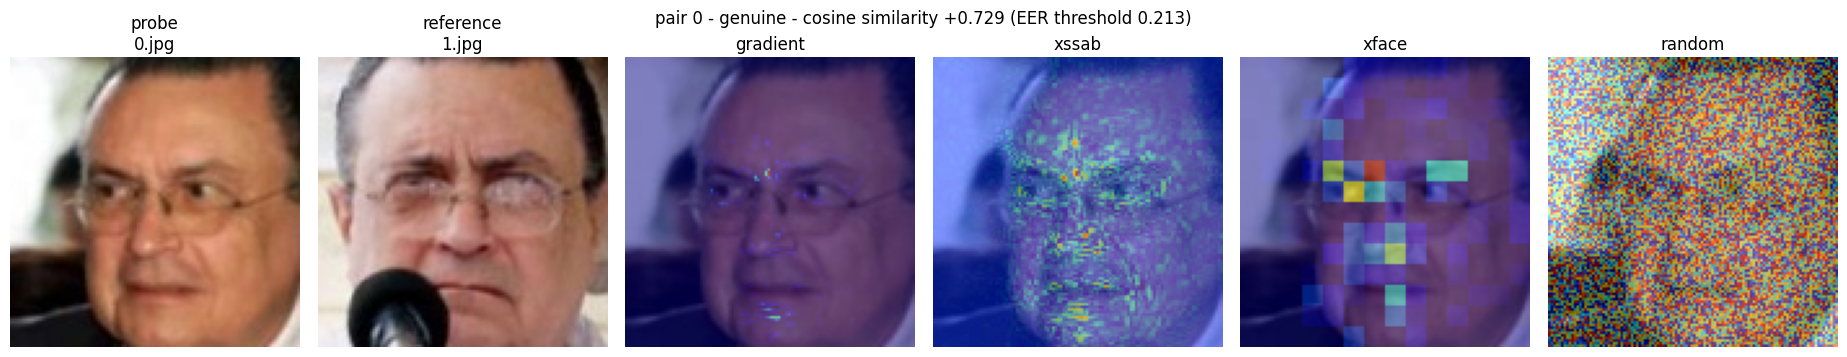

saved /kaggle/working/07_methods_pair1200.png


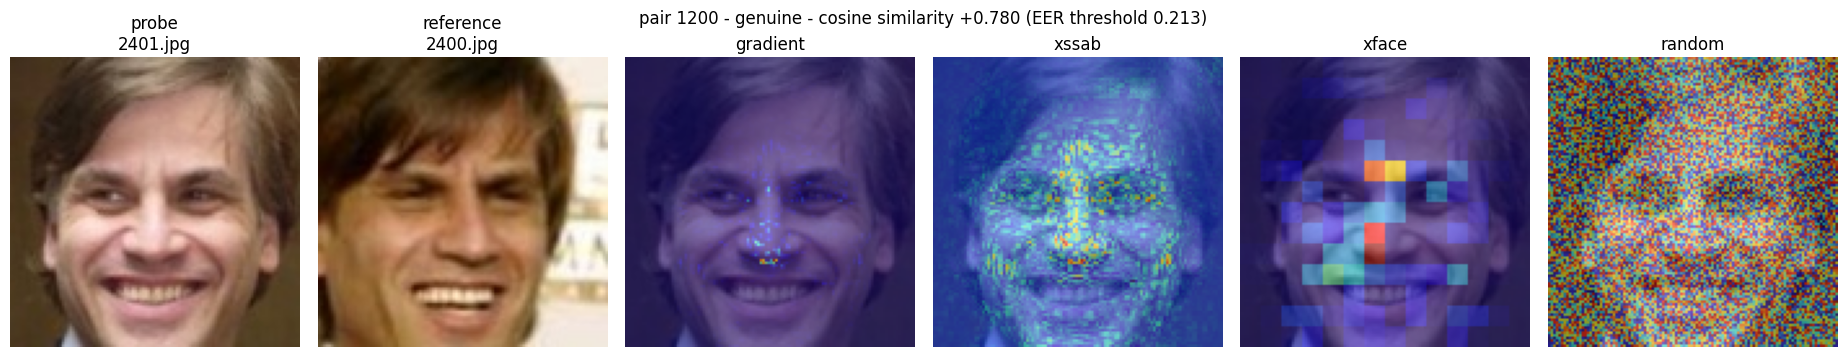

saved /kaggle/working/07_methods_pair3000.png


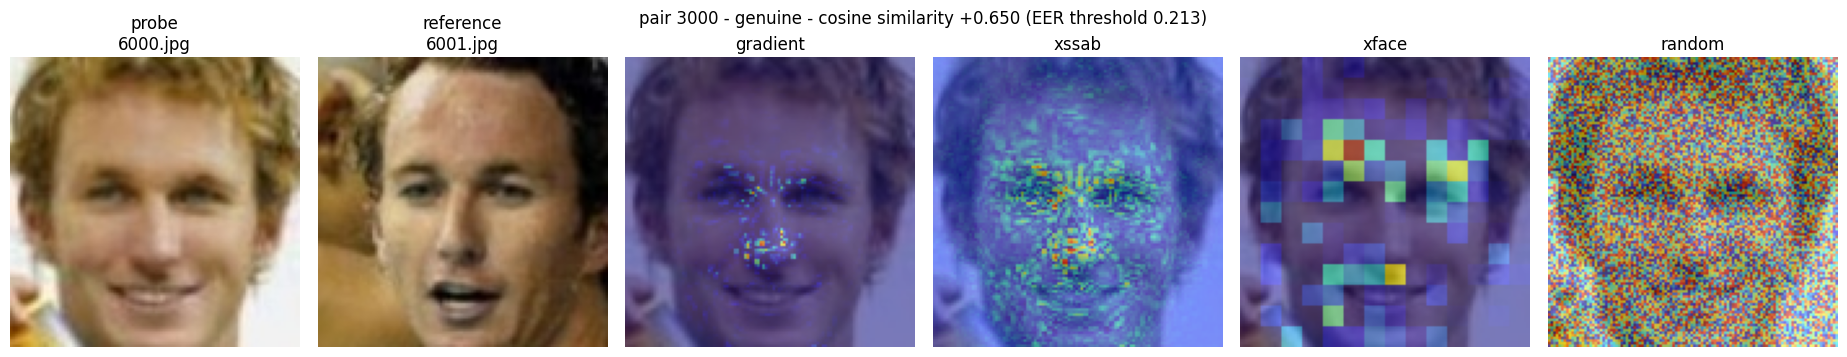

saved /kaggle/working/07_methods_pair300.png


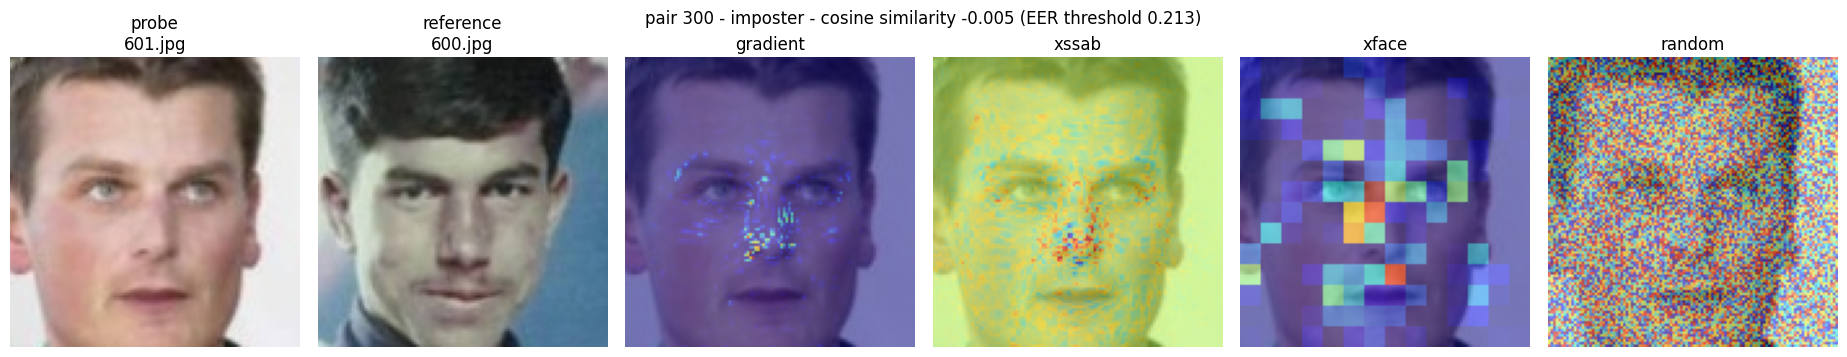

saved /kaggle/working/07_methods_pair3300.png


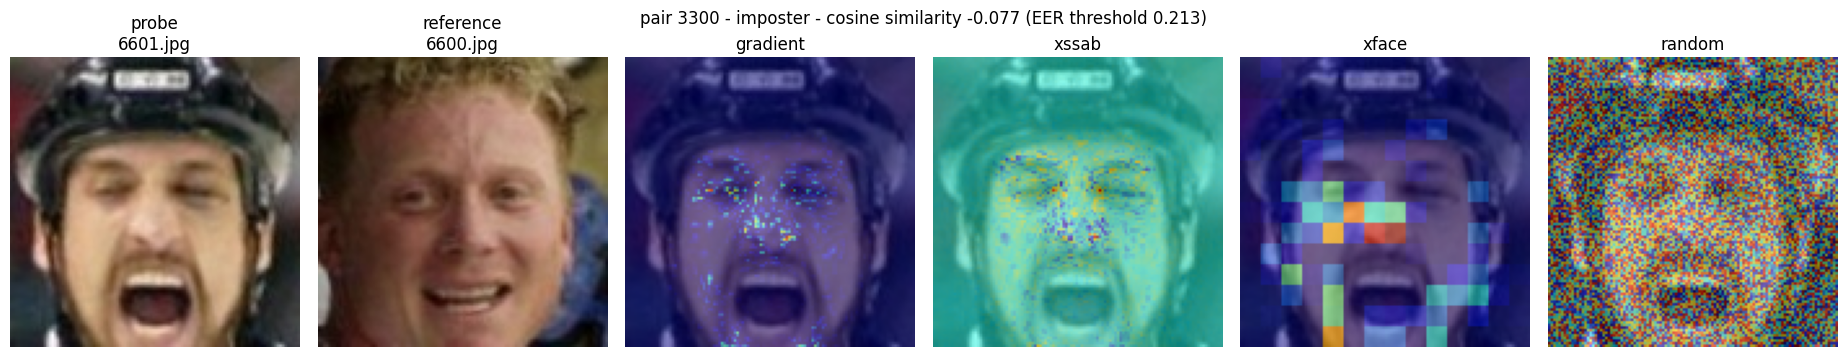

In [22]:
def show_methods(pair_idx):
    probes, refs = load_pair_batch([pair_idx])
    ref_emb = embed_batch(refs)
    sim = float((embed_batch(probes) * ref_emb).sum(1))
    label = "genuine" if IS_GENUINE[pair_idx] else "imposter"
    pr, rf = probe_reference(pair_idx)

    methods = XAI_METHODS_TO_EVAL
    fig, axes = plt.subplots(1, 2 + len(methods), figsize=(3.1 * (2 + len(methods)), 3.6))
    axes[0].imshow(tensor_to_uint8(probes[0])); axes[0].set_title(f"probe\n{pr}.jpg")
    axes[1].imshow(tensor_to_uint8(refs[0]));   axes[1].set_title(f"reference\n{rf}.jpg")
    for k, m in enumerate(methods):
        sal = compute_saliency(m, probes, ref_emb, [pair_idx])[0].cpu().numpy()
        axes[2 + k].imshow(overlay(probes[0], to01(sal)))
        axes[2 + k].set_title(m)
    for a in axes:
        a.axis("off")
    fig.suptitle(f"pair {pair_idx} - {label} - cosine similarity {sim:+.3f} "
                 f"(EER threshold {TAU_EER:.3f})", fontsize=12)
    plt.tight_layout()
    save_fig(f"07_methods_pair{pair_idx}.png")
    plt.show()


for p in VIZ_GENUINE_PAIRS + VIZ_IMPOSTER_PAIRS:
    show_methods(p)

## The full run

Every pair, every method, insertion and deletion. Results are checkpointed to CSV every
`CHECKPOINT_EVERY` pairs so a Kaggle timeout does not cost the whole run.


In [23]:
import time

pairs = PAIR_IDX if MAX_PAIRS is None else PAIR_IDX[:MAX_PAIRS]
methods = XAI_METHODS_TO_EVAL
chunk_list = list(batches(pairs, EVAL_BATCH))
offsets = chunk_offsets(chunk_list)

fwd_per_pair = len(methods) * 2 * (INSDEL_STEPS + 1) + (XFACE_GRID ** 2 if "xface" in methods else 0)
print(f"{len(pairs):,} pairs x {len(methods)} methods, {INSDEL_STEPS + 1} points per curve")
print(f"{len(chunk_list):,} chunks of {EVAL_BATCH} across {len(DEVICES)} GPU(s)")
print(f"~{fwd_per_pair} forward passes per pair -> ~{fwd_per_pair * len(pairs) / 1e6:.2f}M total")

rows = []
curves = {m: {"del": np.zeros((len(pairs), INSDEL_STEPS + 1), np.float32),
              "ins": np.zeros((len(pairs), INSDEL_STEPS + 1), np.float32)}
          for m in methods}


def evaluate_chunk(i, chunk, dev):
    """One chunk of pairs on one GPU. Runs in a worker thread; touches only
    thread-local state and its own slice of the output arrays."""
    probes, refs = load_pair_batch(chunk, device=dev)
    ref_emb = embed_batch(refs)

    batch_rows = [dict(pair_idx=int(p), genuine=bool(IS_GENUINE[p]), fold=int(FOLD[p]),
                       probe_img=int(PROBE_IMG[p]), ref_img=int(REF_IMG[p]),
                       score=float(scores[p]),
                       accepted=bool(scores[p] >= TAU_EER))
                  for p in chunk]

    chunk_curves = {}
    for m in methods:
        sal = compute_saliency(m, probes, ref_emb, chunk)
        dcur, icur = insertion_deletion(probes, ref_emb, sal)
        chunk_curves[m] = (dcur, icur)
        d_auc, i_auc = curve_auc(dcur), curve_auc(icur)
        for r, da, ia in zip(batch_rows, d_auc, i_auc):
            r[f"{m}_del_auc"] = float(da)
            r[f"{m}_ins_auc"] = float(ia)
            r[f"{m}_gap"] = float(ia - da)
    return i, batch_rows, chunk_curves


t0 = time.time()
for i, batch_rows, chunk_curves in parallel_chunks(chunk_list, evaluate_chunk,
                                                   desc="Faithfulness"):
    s = offsets[i]
    for m, (dcur, icur) in chunk_curves.items():
        curves[m]["del"][s:s + len(dcur)] = dcur
        curves[m]["ins"][s:s + len(icur)] = icur
    rows.extend(batch_rows)
    checkpoint_rows(rows, "xai_faithfulness_pairs.csv")

elapsed = time.time() - t0
fdf = pd.DataFrame(rows).sort_values("pair_idx").reset_index(drop=True)
fdf.to_csv(os.path.join(OUTPUT_DIR, "xai_faithfulness_pairs.csv"), index=False)
print(f"done - {len(fdf):,} pairs in {elapsed / 60:.1f} min "
      f"({len(pairs) / max(elapsed, 1e-9):.1f} pairs/s, "
      f"{fwd_per_pair * len(pairs) / max(elapsed, 1e-9):,.0f} forward passes/s)")

6,000 pairs x 4 methods, 21 points per curve
94 chunks of 64 across 2 GPU(s)
~364 forward passes per pair -> ~2.18M total


Faithfulness [2 GPUs]:   0%|          | 0/94 [00:00<?, ?it/s]

done - 6,000 pairs in 46.8 min (2.1 pairs/s, 778 forward passes/s)


## Results

The `gap` column is insertion AUC minus deletion AUC: one number per map for "how well
does this explanation identify the pixels that carry the match", where bigger is better
and the random control marks zero-information.

Genuine and imposter pairs are reported separately, and the genuine rows are the ones
that matter. An imposter pair scores near zero to begin with, so there is very little
match evidence to localise and the curves are nearly flat for every method including
random - the metric simply has little to work with. That is a property of the question,
not a failure of the methods, and it is why notebook 09 attacks accepted genuine pairs.


In [24]:
def summarise(df, title):
    print(f"\n{title}  (n = {len(df):,})")
    print(f"{'method':>10}  {'deletion AUC':>13}  {'insertion AUC':>14}  {'gap (ins-del)':>14}")
    print("-" * 60)
    out = []
    for m in methods:
        d = df[f"{m}_del_auc"].mean()
        i = df[f"{m}_ins_auc"].mean()
        out.append(dict(subset=title, method=m, del_auc=d, ins_auc=i, gap=i - d,
                        del_auc_std=df[f"{m}_del_auc"].std(),
                        ins_auc_std=df[f"{m}_ins_auc"].std()))
        print(f"{m:>10}  {d:>13.4f}  {i:>14.4f}  {i - d:>14.4f}")
    return out


summary = []
summary += summarise(fdf, "all pairs")
summary += summarise(fdf[fdf.genuine], "genuine")
summary += summarise(fdf[~fdf.genuine], "imposter")
summary += summarise(fdf[fdf.genuine & fdf.accepted], "genuine and accepted at EER")
summary_df = pd.DataFrame(summary)
summary_df.to_csv(os.path.join(OUTPUT_DIR, "xai_faithfulness_summary.csv"), index=False)


all pairs  (n = 6,000)
    method   deletion AUC   insertion AUC   gap (ins-del)
------------------------------------------------------------
  gradient         0.0897          0.2816          0.1919
     xssab         0.0991          0.2688          0.1697
     xface         0.0506          0.2917          0.2411
    random         0.1864          0.2425          0.0561

genuine  (n = 3,000)
    method   deletion AUC   insertion AUC   gap (ins-del)
------------------------------------------------------------
  gradient         0.1793          0.5597          0.3803
     xssab         0.1971          0.5319          0.3349
     xface         0.1772          0.5287          0.3516
    random         0.3698          0.4806          0.1108

imposter  (n = 3,000)
    method   deletion AUC   insertion AUC   gap (ins-del)
------------------------------------------------------------
  gradient         0.0001          0.0036          0.0034
     xssab         0.0012          0.0056          0

### Sanity check on the metric itself

If the real explanation methods do not beat uniform noise, the insertion/deletion
implementation is broken and nothing downstream is trustworthy. This asserts they do, on
genuine pairs.


In [25]:
gen = fdf[fdf.genuine]
rand_gap = (gen["random_ins_auc"] - gen["random_del_auc"]).mean()
print(f"random control gap : {rand_gap:+.4f}   <- the 'no explanation' floor")
for m in methods:
    if m == "random":
        continue
    gap = (gen[f"{m}_ins_auc"] - gen[f"{m}_del_auc"]).mean()
    verdict = "OK" if gap > rand_gap else "FAILS - investigate"
    print(f"{m:>10} gap      : {gap:+.4f}   {verdict}")

assert all((gen[f"{m}_ins_auc"] - gen[f"{m}_del_auc"]).mean() > rand_gap
           for m in methods if m != "random"), \
    "an explanation method is no better than random - insertion/deletion is misconfigured"
print("\nAll explanation methods beat the random floor.")

random control gap : +0.1108   <- the 'no explanation' floor
  gradient gap      : +0.3803   OK
     xssab gap      : +0.3349   OK
     xface gap      : +0.3516   OK

All explanation methods beat the random floor.


## Mean curves

The shape carries more information than the AUC. A faithful deletion curve falls off a
cliff in the first few percent of pixels and then flattens; a faithful insertion curve
does the mirror image. The random control is the near-straight diagonal that shows what
a map with no information looks like on this model.


saved /kaggle/working/07_insertion_deletion_curves.png


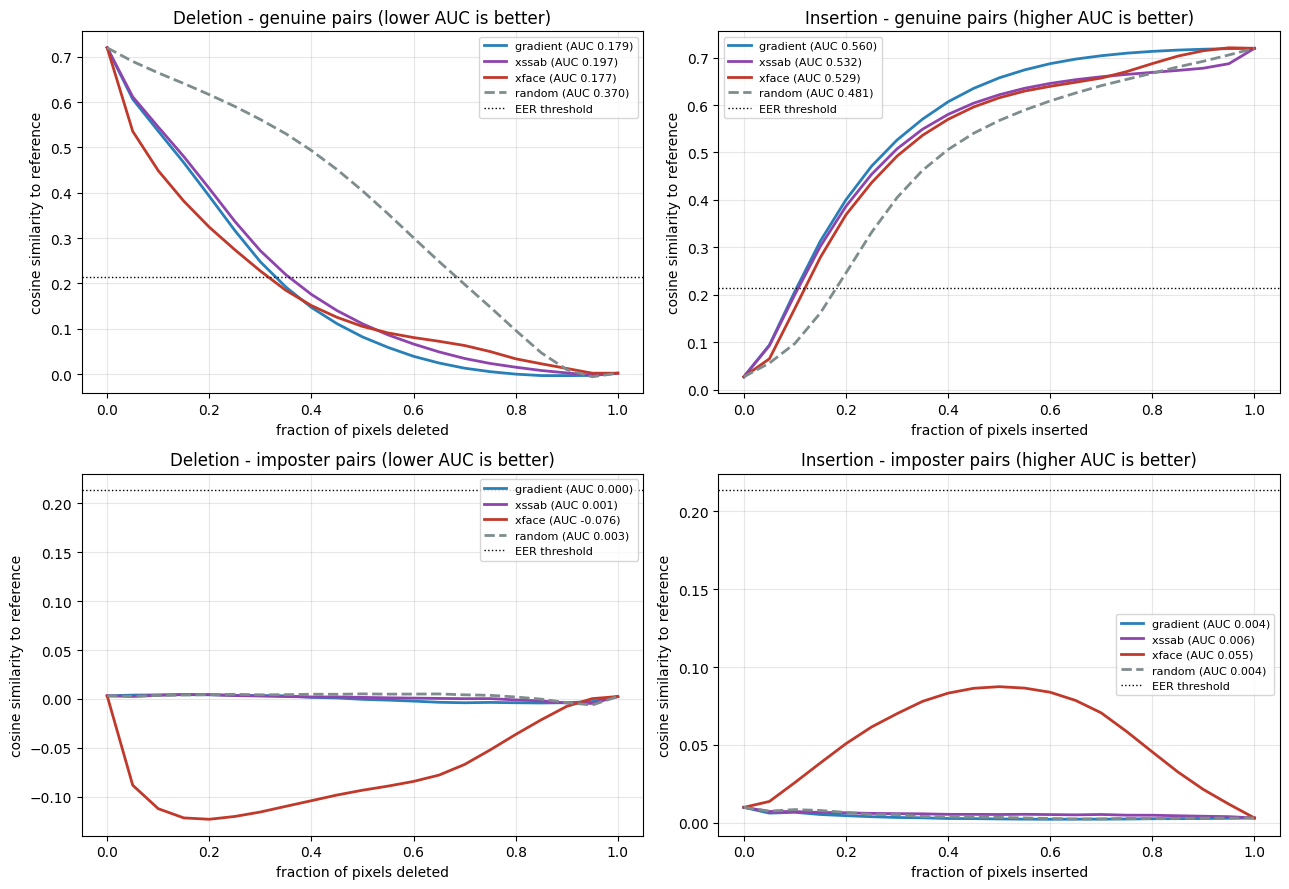

In [26]:
x = np.linspace(0, 1, INSDEL_STEPS + 1)
colors = {"gradient": "#2980b9", "xssab": "#8e44ad", "xface": "#c0392b", "random": "#7f8c8d"}
subsets = [("genuine", IS_GENUINE[pairs]), ("imposter", ~IS_GENUINE[pairs])]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for r, (name, mask) in enumerate(subsets):
    for c, kind in enumerate(["del", "ins"]):
        ax = axes[r, c]
        for m in methods:
            mean_curve = curves[m][kind][mask].mean(0)
            ax.plot(x, mean_curve, lw=2, label=f"{m} (AUC {curve_auc(mean_curve):.3f})",
                    color=colors.get(m), ls="--" if m == "random" else "-")
        ax.axhline(TAU_EER, color="k", ls=":", lw=1, label=f"EER threshold")
        ax.set_xlabel("fraction of pixels " + ("deleted" if kind == "del" else "inserted"))
        ax.set_ylabel("cosine similarity to reference")
        ax.set_title(f"{'Deletion' if kind == 'del' else 'Insertion'} - {name} pairs "
                     f"({'lower' if kind == 'del' else 'higher'} AUC is better)")
        ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout(); save_fig("07_insertion_deletion_curves.png"); plt.show()

saved /kaggle/working/07_auc_bars.png


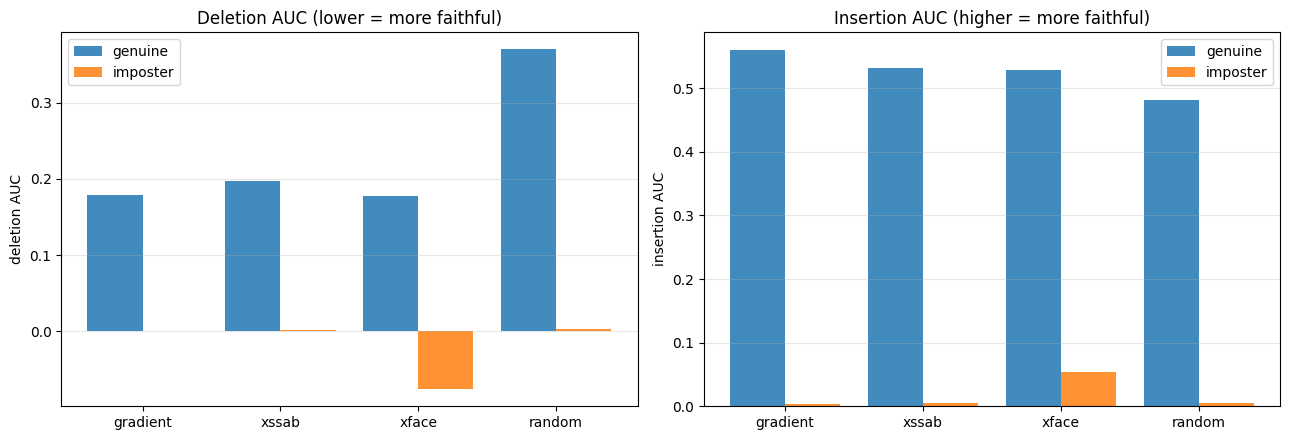

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
real = [m for m in methods if m != "random"]

ax = axes[0]
w = 0.8 / 2
for k, (label, sub) in enumerate([("genuine", fdf[fdf.genuine]), ("imposter", fdf[~fdf.genuine])]):
    ax.bar(np.arange(len(methods)) + k * w, [sub[f"{m}_del_auc"].mean() for m in methods],
           width=w, label=label, alpha=0.85)
ax.set_xticks(np.arange(len(methods)) + w / 2); ax.set_xticklabels(methods)
ax.set_ylabel("deletion AUC"); ax.set_title("Deletion AUC (lower = more faithful)")
ax.legend(); ax.grid(alpha=0.3, axis="y")

ax = axes[1]
for k, (label, sub) in enumerate([("genuine", fdf[fdf.genuine]), ("imposter", fdf[~fdf.genuine])]):
    ax.bar(np.arange(len(methods)) + k * w, [sub[f"{m}_ins_auc"].mean() for m in methods],
           width=w, label=label, alpha=0.85)
ax.set_xticks(np.arange(len(methods)) + w / 2); ax.set_xticklabels(methods)
ax.set_ylabel("insertion AUC"); ax.set_title("Insertion AUC (higher = more faithful)")
ax.legend(); ax.grid(alpha=0.3, axis="y")

plt.tight_layout(); save_fig("07_auc_bars.png"); plt.show()

## Save


In [28]:
np.savez_compressed(
    os.path.join(OUTPUT_DIR, "xai_curves_mean.npz"),
    x=x, pairs=pairs, is_genuine=IS_GENUINE[pairs],
    **{f"{m}_{k}_mean_{name}": curves[m][k][mask].mean(0)
       for m in methods for k in ("del", "ins")
       for name, mask in subsets},
    **{f"{m}_{k}_all": curves[m][k] for m in methods for k in ("del", "ins")},
)
with open(os.path.join(OUTPUT_DIR, "xai_config.json"), "w") as fh:
    json.dump(dict(methods=methods, insdel_steps=INSDEL_STEPS,
                   delete_value=DELETE_VALUE, insert_blur_sigma=INSERT_BLUR_SIGMA,
                   xface_grid=XFACE_GRID, xssab_thr=XSSAB_THR,
                   eer_threshold=TAU_EER, eer=EER, n_pairs=int(len(pairs))), fh, indent=2)
print("saved xai_faithfulness_pairs.csv, xai_faithfulness_summary.csv, "
      "xai_curves_mean.npz, xai_config.json")

saved xai_faithfulness_pairs.csv, xai_faithfulness_summary.csv, xai_curves_mean.npz, xai_config.json


## Results and discussion

**The explanations are faithful, and that is now a measurement rather than an
impression.** On the 3,000 genuine pairs every method separates decisively from the
uniform-noise floor. Deleting the pixels they rank highest collapses the similarity far
faster than deleting random pixels (deletion AUC 0.177-0.197 against 0.370 for random),
and restoring those same pixels rebuilds it faster (insertion AUC 0.529-0.560 against
0.481). On the insertion-minus-deletion gap the effect size against random is **Cohen's
d = 3.4** - the methods are not marginally better than noise, they are in a different
regime. Notebook 02's "the maps look sensible" on eight hand-picked pairs is now a
quantitative claim over 6,000.

**The implementation validates on its endpoints.** All four methods share identical curve
endpoints - deletion begins at the true mean similarity 0.7196 and ends at 0.0019 (a
uniformly grey probe), insertion begins at 0.0272 (a fully blurred probe) and ends at
0.7196 - because those are properties of the start and end states, not of the ranking.
Only the *path between them* differs, which is exactly what the AUC measures.

**Ranking the methods, honestly.** On genuine pairs the gap ordering is gradient (0.380),
xFace (0.352), xSSAB (0.335). All differences are statistically significant at n = 3,000,
but the effect sizes are what matter: gradient beats xSSAB by d = 1.14, but gradient beats
xFace by only d = 0.31 and xFace beats xSSAB by d = 0.16. **The spread between the three
methods is far smaller than the distance from any of them to random.** Two caveats before
reading anything into the ordering. First, the comparison is not apples-to-apples: xFace
is grid-based, so its map is piecewise constant over 8x8 blocks and cannot express
pixel-level structure, which handicaps it on a pixel-ranked metric while the raw gradient
map is pixel-sharp and is flattered by it. Second, the xSSAB figure here uses the
*combined* actor-minus-counteractor map; the actor map alone (`xssab_actor`) is arguably
the more natural choice for "which pixels support this match" and is worth evaluating
before drawing conclusions about the method.

**Imposter pairs are degenerate for this metric, and xFace shows it dramatically.** With a
base similarity of 0.003 there is essentially no match evidence to localise, so all
methods trace nearly flat curves and the AUCs collapse toward zero. xFace is the exception
and its **deletion AUC goes negative (-0.076)**: its curve dips to -0.123 after only 20% of
pixels are deleted before returning to 0.003. This is not a bug. xFace ranks cells by how
far similarity *drops* when they are occluded, so on an imposter pair it correctly
identifies the handful of regions supplying what little positive evidence exists, and
removing them first drives the score well below zero. The consequence is that the
insertion-minus-deletion gap is not comparable across the genuine and imposter subsets:
it implicitly assumes a curve bounded near zero from below, which holds for a rejected
pair only if the map is uninformative. **Read the genuine rows; treat the imposter rows as
a diagnostic of the metric, not a ranking of the methods.** For the same reason the "all
pairs" row - a straight average of a meaningful and a degenerate population - should not
be quoted on its own.

**What this implies for notebook 09.** The distance from each method to the random floor
is the room the attack has to work in, and it is very asymmetric:

| | current | random floor | headroom |
|---|---|---|---|
| deletion AUC (gradient) | 0.179 | 0.370 | **+0.191** |
| insertion AUC (gradient) | 0.560 | 0.481 | -0.079 |

**The deletion curve will carry the signal; insertion has little room to move.** Random
insertion already reaches an AUC of 0.481 because restoring *any* half of the pixels over
a blurred baseline recovers most of the similarity - the metric is intrinsically weak at
discriminating orderings in this setting. Notebook 09 reports both, but a successful
attack should be judged mainly on deletion AUC rising toward 0.370.

**Limitations.** Insertion/deletion has a known confound: masking creates
out-of-distribution inputs, and part of any score change comes from the mask artefact
rather than from removing informative content. The blurred insertion baseline and the
mid-grey deletion baseline are the standard mitigations, and the random control absorbs
most of what remains since it suffers the same artefact - but it is not eliminated. the Patch-LFW
benchmark attacks the same problem from a different angle (replace pixels by
importance rank and measure the FMR/FNMR shift); implementing it here would require the
patch dataset from the xSSAB repository and is left as future work.

**Next.** Notebook 08 fixes the decision attacks; notebook 09 runs the explanation attack
and re-measures everything computed here.
